# Co-registering the WaldoAir Camp Fire mosaic to the lidar

The WaldoAir mosaic (4 cm pixels) fits the lidar
buildings well in the middle of Paradise but is several metres off in places,
more so towards the edges. The shifts are local, not one shift or one scale for
the whole image, so the likely cause is **relief displacement**: the mosaic was
orthorectified onto a flat or too coarse height model, and wherever the true
ground differs from it, the image is pushed sideways by
(height error) × tan(view angle).

We cannot redo the orthorectification (we have no camera positions), so we will fix
it empirically: **co-registration** to the lidar, which we trust.

1. **Image matching** (this notebook, part 1 and 2): on a grid of cells, find
   the shift (dx, dy) at which the image fits the lidar best. Each cell gives a
   *tie point* (an automatic ground control point, GCP).
2. **Understand** the shifts: do they follow the terrain, or jump at the seams
   between photos?
3. **Rubber-sheeting**: warp the image so the tie points line up, and write a
   *new* COG (the original stays untouched).

**Sign convention.** (dx, dy) is where the image shows a feature minus where
the lidar has it, in metres (east, north). To fix the image, it must move by
(−dx, −dy).

## Setup

We use **version 2** of the mosaic: the 495 tiles in
`/media/disk1/waldoair_campfire_data/` (updated 2026-11-05, no missing tiles),
from which `waldoair_campfire_web_v2.tif` was built. That web COG is these
tiles reprojected to EPSG:3857, so it carries the same error. We measure and
correct in the tiles' own frame, and then build a new web COG from the
corrected version.

To read the 495 tiles as one image, we make a **VRT** of them: a small XML
file that lists the tiles and where each one sits. It copies no pixels, and
the tiles' own overviews make reading it at 0.5 m fast.

First we will measure in the mosaic's own coordinates, so the tie points apply directly to
the original file. Its CRS is a local *ENU* frame (east, north, up) around a
point in the middle of Paradise, stored as an Orthographic projection: a flat
plane that touches the Earth at that point. Its units are metres.

`geo` kernel (rasterio, geopandas, scipy, matplotlib).

In [1]:
import os
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject
from rasterio.windows import from_bounds
from scipy import ndimage, signal

# GDAL's Python side in this environment does not find PROJ's database by
# itself; pyproj knows where it is.
os.environ.setdefault('PROJ_DATA', pyproj.datadir.get_data_dir())
from osgeo import gdal  # noqa: E402

gdal.UseExceptions()

TILES = Path('/media/disk1/waldoair_campfire_data')  # version 2 of the mosaic, 495 tiles
# The VRT of all tiles: the mosaic as it is. Called COG below, as it is read
# like one.
COG = '/media/disk1/waldoair_campfire_cog/waldoair_campfire_v2.vrt'
RUN = Path('/home/michael/Work/detection/runs2/camp_fire_prefire')
BUILDINGS = RUN / 'buildings.gpkg'  # lidar building footprints, EPSG:6339
NDSM = RUN / 'ndsm.vrt'             # lidar height above ground, 0.5 m, EPSG:6339

RES = 0.5      # m; matching resolution (the COG has overviews, so reading coarser is fast)
CELL = 200.0   # m; side of one matching cell
SEARCH = 15.0  # m; largest shift we look for, in each direction

if not Path(COG).exists():
    gdal.BuildVRT(COG, sorted(str(tile) for tile in TILES.glob('*.tif'))).Close()

In [2]:
cog = rasterio.open(COG)
print(cog.crs.to_wkt()[:70], '...')
print('bounds (m):', cog.bounds)
print('pixel (m):', cog.res, ' overviews:', cog.overviews(1))

ndsm = rasterio.open(NDSM)
buildings = gpd.read_file(BUILDINGS).to_crs(cog.crs)
print(len(buildings), 'lidar buildings')

PROJCS["ENU (-121.604502775868:39.7642484434766) + EGM96 geoid height" ...
bounds (m): BoundingBox(left=-4027.416825, bottom=-4458.955709000001, right=3957.901593000001, top=4452.593539)
pixel (m): (0.041111, 0.041111)  overviews: [2, 4, 8, 16, 32, 64]


23192 lidar buildings


## Reading a window from both

For one square of ground, `read_image` and `read_ndsm` return arrays on exactly
the same grid: same corner, same pixel size (`RES`), in the COG's CRS. The
image is read from an overview (rasterio picks it when we ask for fewer
pixels), averaged to grey. The nDSM is reprojected from EPSG:6339 onto the
grid and clipped at 30 m, so a few tall trees do not dominate.

In [3]:
def window_grid(left, bottom, right, top, res=RES):
    '''The size and transform of a grid of res-m pixels over these bounds.'''
    n_cols, n_rows = int(round((right - left) / res)), int(round((top - bottom) / res))
    return (n_rows, n_cols), from_origin(left, top, res, res)


def read_image(bounds, res=RES):
    '''The mosaic over bounds, as grey (mean of R, G, B), at res m.'''
    shape, _ = window_grid(*bounds, res)
    rgb = cog.read([1, 2, 3], window=from_bounds(*bounds, cog.transform),
                   out_shape=(3, *shape), resampling=Resampling.average)
    return rgb.astype(float).mean(axis=0)


def read_ndsm(bounds, res=RES):
    '''The lidar height above ground over bounds, on the same grid as read_image.'''
    shape, transform = window_grid(*bounds, res)
    out = np.zeros(shape, 'float32')
    reproject(rasterio.band(ndsm, 1), out, dst_transform=transform, dst_crs=cog.crs,
              resampling=Resampling.bilinear)
    return np.clip(np.nan_to_num(out), 0, 30)

## Matching

### Why edges

The image and the nDSM measure different things: the image is colour, the
nDSM is height. A grey roof can sit next to grey asphalt, so in the image it
barely stands out, while in the nDSM it is a 6 m step. So we do not compare the
values themselves, but **where they change**: a roof edge, the edge of a tree
crown, or the rim of a burned house's ash is an edge in both.

`edges` does that in three steps:

1. **Smooth** a little (Gaussian, σ = 1.5 px = 0.75 m), so noise and texture
   (shingles, gravel, leaves) do not count as edges.
2. **Gradient magnitude** (Sobel): at each pixel, how fast the value changes,
   in any direction. Flat areas become 0, edges become large.
3. **Standardise**: subtract the mean and divide by the standard deviation.
   Then the image (grey levels 0–255) and the nDSM (metres) are on the same
   scale, and only the pattern counts.

### Sliding the lidar over the image

For one cell, we take the lidar edges over the cell itself (`CELL` × `CELL`
m), and the image edges over the cell plus `SEARCH` m on every side. We then
slide the lidar patch over the image patch, one pixel (0.5 m) at a time, to
every position where it still fits inside: that is every shift from −`SEARCH`
to +`SEARCH` m east and north, (2 × 30 + 1)² = 3,721 shifts.

At each shift, the **score** is the correlation between the two edge maps:
multiply them pixel by pixel and average. Where an edge in the lidar lands on
an edge in the image, both are large and the product adds a lot; where it lands
on a flat area, it adds little. So the score is highest at the shift where most
lidar edges land on image edges: that shift is the answer.
`scipy.signal.correlate(..., mode='valid')` computes all 3,721 scores at once
(`valid`: only the shifts where the lidar patch lies fully inside the image
patch).

`score` is a small image of its own: the centre pixel `[k, k]` is no shift,
one pixel to the right is 0.5 m east, one pixel down is 0.5 m **south** (rows
of an image run from north to south, hence the minus sign for `dy`).

### Can we trust it?

The highest score always wins, even in a cell where nothing fits. A real match
is a sharp peak that stands well above the scores of all other shifts. `z`
measures that: how many standard deviations the peak lies above the median of
the other scores (those more than 2 m from the peak).

- `z` of 4 or more: a clear peak (part 2 shows how we chose 4);
- `z` around 3 or less: other shifts fit nearly as well (forest, open ground,
  a repeating pattern such as rows of mobile homes), and the cell cannot be
  trusted.

(A first version divided the peak by the second-best score. That fails where
the scores lie around 0: dividing two numbers near zero gives anything from
−300 to +30,000.)

`on_border` is true when the peak lies on the edge of the search area, at
±`SEARCH` m. Then the true shift may be larger than we searched for, and the
cell cannot be trusted either.

The figure after the code shows the steps for the south-east cell.

In [4]:
def edges(array, sigma=1.5):
    '''Standardised gradient magnitude: where the array changes.'''
    smooth = ndimage.gaussian_filter(array.astype(float), sigma)
    gradient = np.hypot(ndimage.sobel(smooth, 0), ndimage.sobel(smooth, 1))
    return (gradient - gradient.mean()) / (gradient.std() + 1e-9)


def match(x, y, cell=CELL, search=SEARCH, res=RES):
    '''The shift (dx, dy) of the image relative to the lidar in the cell centred on (x, y).

    Returns dx, dy (m), the correlation at the peak, z (how many standard
    deviations the peak stands above the other shifts), and on_border (the
    peak is at the largest shift searched).
    '''
    half = cell / 2 + search
    bounds = (x - half, y - half, x + half, y + half)
    image = edges(read_image(bounds, res))
    k = int(round(search / res))  # the margin in pixels
    lidar = edges(read_ndsm(bounds, res))[k:-k, k:-k]
    lidar = (lidar - lidar.mean()) / (lidar.std() + 1e-9)
    # score[i, j] is the correlation with the lidar moved j - k pixels east
    # and i - k pixels south (rows run southwards).
    score = signal.correlate(image, lidar, mode='valid') / lidar.size
    i, j = np.unravel_index(np.argmax(score), score.shape)
    peak = score[i, j]
    near = int(round(2 / res))
    rest = score.copy()
    rest[max(0, i - near):i + near + 1, max(0, j - near):j + near + 1] = np.nan
    z = (peak - np.nanmedian(rest)) / np.nanstd(rest)
    on_border = i in (0, 2 * k) or j in (0, 2 * k)
    return (j - k) * res, -(i - k) * res, peak, z, on_border

### The steps in pictures

For the south-east cell: the image, its edges, the lidar nDSM, its edges, and
the score of every shift. The cross marks no shift, the circle the best one.

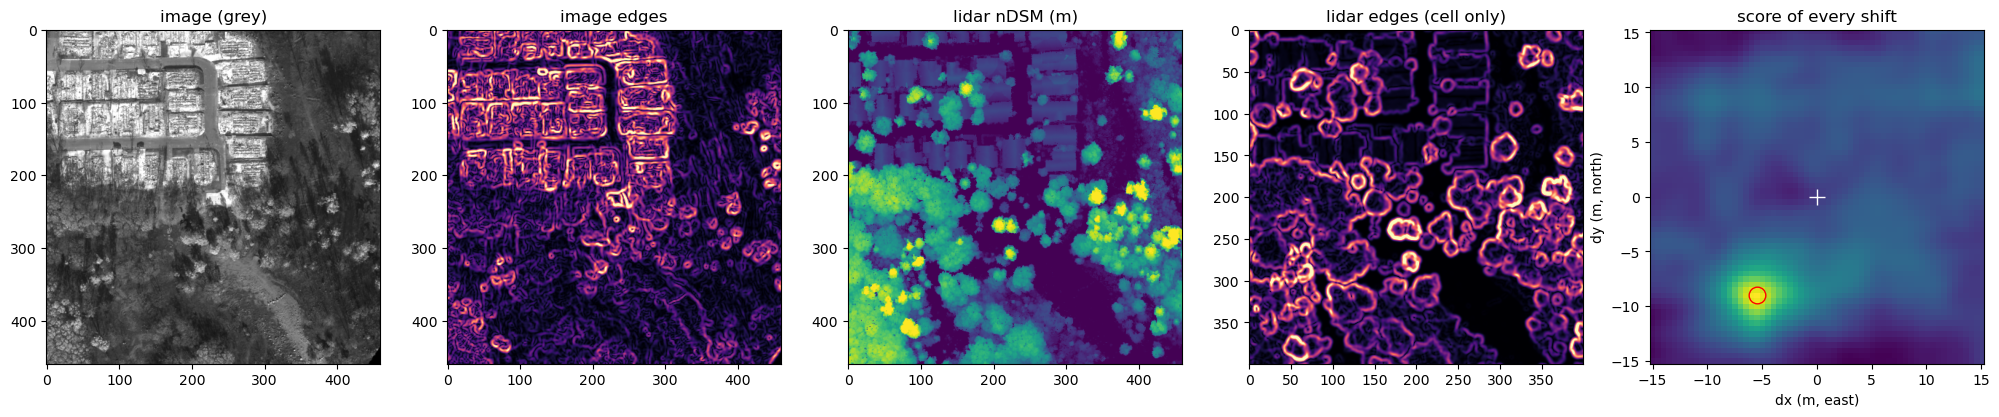

In [5]:
x, y = 3300, -3900
half = CELL / 2 + SEARCH
bounds = (x - half, y - half, x + half, y + half)
k = int(round(SEARCH / RES))
image, height = read_image(bounds), read_ndsm(bounds)
image_edges, lidar_edges = edges(image), edges(height)[k:-k, k:-k]
lidar_edges = (lidar_edges - lidar_edges.mean()) / lidar_edges.std()
score = signal.correlate(image_edges, lidar_edges, mode='valid') / lidar_edges.size
i, j = np.unravel_index(np.argmax(score), score.shape)

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
panels = [(image, 'gray', 'image (grey)'), (image_edges, 'magma', 'image edges'),
          (height, 'viridis', 'lidar nDSM (m)'), (lidar_edges, 'magma', 'lidar edges (cell only)')]
for ax, (array, cmap, title) in zip(axes, panels):
    ax.imshow(array, cmap=cmap, vmax=np.percentile(array, 99))
    ax.set_title(title)
extent = (-SEARCH - RES / 2, SEARCH + RES / 2, -SEARCH - RES / 2, SEARCH + RES / 2)
axes[4].imshow(score, cmap='viridis', extent=extent)
axes[4].plot(0, 0, 'w+', markersize=12)
axes[4].plot((j - k) * RES, -(i - k) * RES, 'ro', markerfacecolor='none', markersize=12)
axes[4].set_xlabel('dx (m, east)')
axes[4].set_ylabel('dy (m, north)')
axes[4].set_title('score of every shift')
plt.show()

## Test on two cells

One near the centre of the mosaic and one near its south-east edge, both in
built-up Paradise.

In [6]:
tests = {'centre': (100, -100), 'south-east edge': (3300, -3900)}
shifts = {}
for name, (x, y) in tests.items():
    dx, dy, peak, z, on_border = match(x, y)
    shifts[name] = (dx, dy)
    print(f'{name:16} ({x}, {y}): dx {dx:+.1f} m, dy {dy:+.1f} m, '
          f'|shift| {np.hypot(dx, dy):.1f} m, peak {peak:.3f}, z {z:.1f}')

centre           (100, -100): dx -1.5 m, dy +1.0 m, |shift| 1.8 m, peak 0.119, z 3.5
south-east edge  (3300, -3900): dx -5.5 m, dy -9.0 m, |shift| 10.5 m, peak 0.115, z 7.7


## Check by eye

Left: the lidar building outlines over the original image. Right: the
outlines moved by the measured (dx, dy). If the match is right, they now sit
on the roofs and ash rectangles.

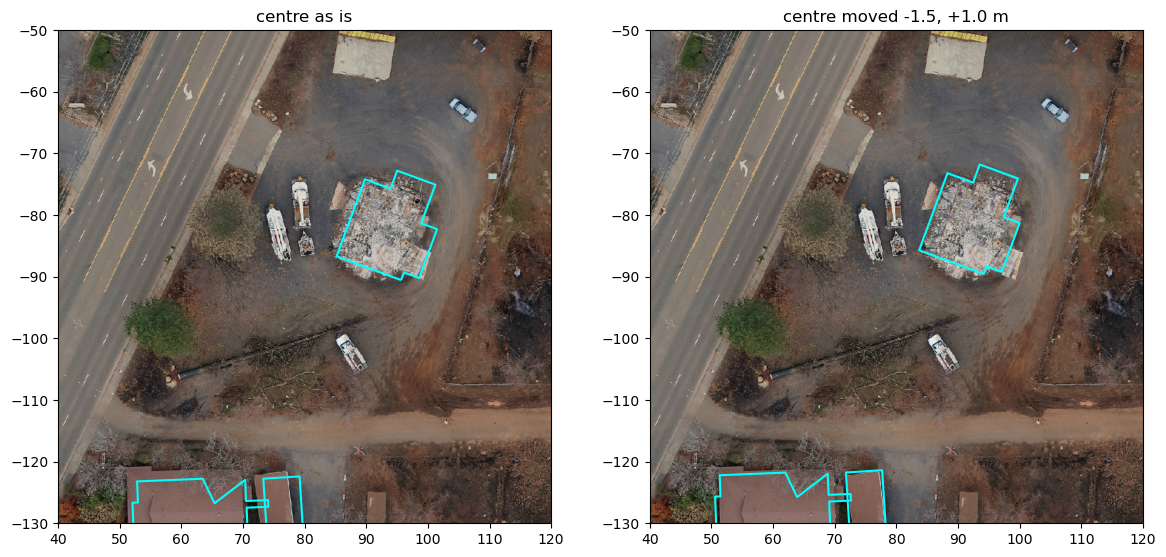

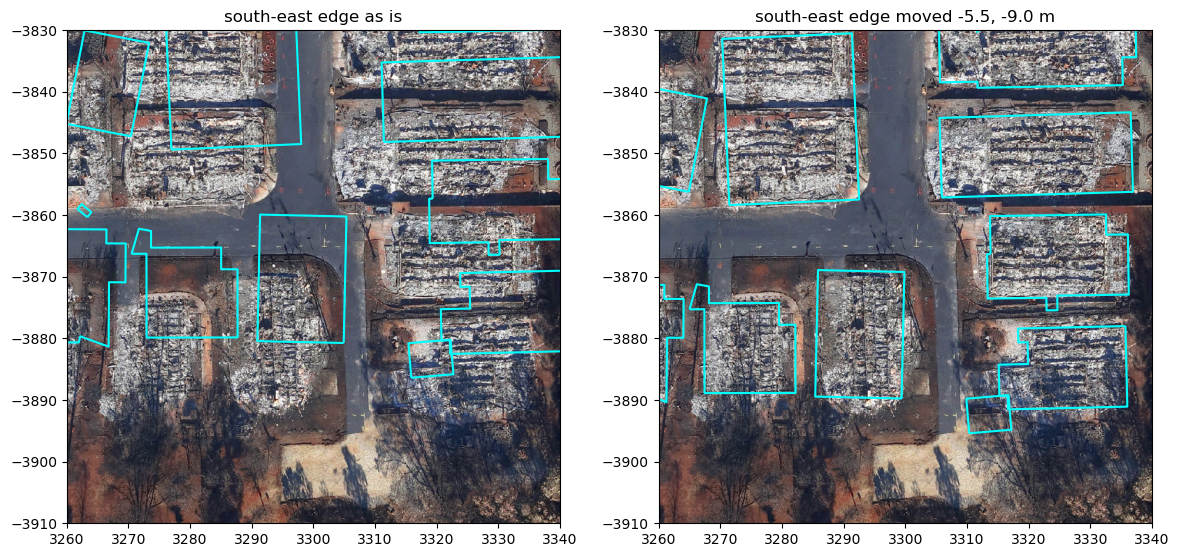

In [7]:
def show(x, y, dx, dy, size=80, title=''):
    '''The image around (x, y) with lidar outlines, as they are and moved by (dx, dy).'''
    bounds = (x - size / 2, y - size / 2, x + size / 2, y + size / 2)
    left, bottom, right, top = bounds
    rgb = cog.read([1, 2, 3], window=from_bounds(*bounds, cog.transform), out_shape=(3, 800, 800))
    outlines = buildings.cx[left - 20:right + 20, bottom - 20:top + 20].boundary
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, (sx, sy), label in zip(axes, [(0, 0), (dx, dy)], ['as is', f'moved {dx:+.1f}, {dy:+.1f} m']):
        ax.imshow(np.moveaxis(rgb, 0, -1), extent=(left, right, bottom, top))
        outlines.translate(sx, sy).plot(ax=ax, color='cyan', linewidth=1.5)
        ax.set_xlim(left, right)
        ax.set_ylim(bottom, top)
        ax.set_title(f'{title} {label}')
    plt.show()


show(80, -90, *shifts['centre'], title='centre')
show(3300, -3870, *shifts['south-east edge'], title='south-east edge')

Both fit. Even the centre is off by almost 2 m, and the south-east edge by
about 10 m: far too much for an error in the CRS (that would be under half a
metre), so it is the orthorectification.

**Next (part 2):** run `match` on a grid of cells over the whole mosaic, keep
the trustworthy ones, and write them as tie points to a GeoPackage to look at
in QGIS.

# Part 2: the whole mosaic

A grid of cells, `CELL` m apart, over the COG's bounds. Before matching a
cell, we read it coarsely (4 m) and skip it if more than 10% of it is black: a good part of the
rectangle around the mosaic lies outside it.

For every cell we also note, for part 3:

- `ground`: the mean lidar ground height (DTM) in the cell, m above sea level
  (NAVD88). If the vendor orthorectified onto a too smooth or flat height
  model, the shift should depend on it.
- `relief`: highest minus lowest ground in the cell, m: steep ground or a
  canyon.
- `lidar`: whether the lidar there was flown `before` or `after` the fire
  (west of Paradise it is post-fire; that matches the image even better).

The grid takes about 2 minutes.

In [8]:
DTM = RUN / 'dtm.vrt'        # lidar ground height, 0.5 m, EPSG:6339
FLOWN = RUN / 'flown.gpkg'   # where the lidar was flown before or after the fire
MAX_BLACK = 0.1              # skip a cell with more black (no image) than this
dtm = rasterio.open(DTM)


def ground_heights(bounds, res=5):
    '''The lidar ground height over bounds, at res m.'''
    shape, transform = window_grid(*bounds, res)
    out = np.zeros(shape, 'float32')
    reproject(rasterio.band(dtm, 1), out, dst_transform=transform, dst_crs=cog.crs,
              resampling=Resampling.bilinear)
    return out


half = CELL / 2 + SEARCH
left, bottom, right, top = cog.bounds
rows = []
for y in np.arange(top - half, bottom + half, -CELL):
    for x in np.arange(left + half, right - half, CELL):
        bounds = (x - half, y - half, x + half, y + half)
        if (read_image(bounds, res=4) == 0).mean() > MAX_BLACK:
            continue
        dx, dy, peak, z, on_border = match(x, y)
        ground = ground_heights(bounds)
        rows.append({'x': x, 'y': y, 'dx': dx, 'dy': dy, 'shift': np.hypot(dx, dy),
                     'peak': peak, 'z': z, 'on_border': on_border,
                     'ground': ground.mean(), 'relief': ground.max() - ground.min()})

cells = gpd.GeoDataFrame(rows, geometry=gpd.points_from_xy([r['x'] for r in rows], [r['y'] for r in rows]),
                         crs=cog.crs)
flown = gpd.read_file(FLOWN).to_crs(cog.crs)
period = gpd.sjoin(cells[['geometry']], flown[['period', 'geometry']], predicate='within')
cells['lidar'] = period.groupby(level=0)['period'].first().replace('both', 'before')
print(f'{len(cells)} cells with image')
print(cells['lidar'].value_counts().to_string())

1192 cells with image
lidar
before    1020
after      172


## Choosing the threshold for z

The true shift changes smoothly from place to place (it follows the ground and
the camera), so a cell we can trust should agree with its neighbours. For
every cell, `deviation` is the distance (m) between its shift and the median
shift of its (up to 8) neighbours. It needs no threshold of its own, so we use
it to judge `z`: per range of `z`, how many cells lie within 2 m of their
neighbours.

In [9]:
position = {(round(x), round(y)): n for n, (x, y) in enumerate(zip(cells['x'], cells['y']))}
deviation = []
for x, y, dx, dy in zip(cells['x'], cells['y'], cells['dx'], cells['dy']):
    around = [position.get((round(x + a * CELL), round(y + b * CELL)))
              for a in (-1, 0, 1) for b in (-1, 0, 1) if a or b]
    around = [n for n in around if n is not None]
    if len(around) < 3:
        deviation.append(np.nan)
        continue
    deviation.append(np.hypot(dx - cells['dx'].iloc[around].median(), dy - cells['dy'].iloc[around].median()))
cells['deviation'] = deviation

by_z = cells.groupby(pd.cut(cells['z'], [0, 3, 3.5, 4, 4.5, 5, 6, 8, np.inf]), observed=True)
by_z.agg(cells=('z', 'size'),
         median_deviation_m=('deviation', 'median'),
         within_2_m=('deviation', lambda d: f'{(d < 2).mean():.0%}'),
         on_border=('on_border', lambda b: f'{b.mean():.0%}'))

,cells,median_deviation_m,within_2_m,on_border
z,,,,
"(0.0, 3.0]",271,16.087651,17%,39%
"(3.0, 3.5]",108,11.626330,42%,29%
"(3.5, 4.0]",83,0.559017,78%,10%
"(4.0, 4.5]",90,0.707107,82%,3%
"(4.5, 5.0]",90,0.500000,91%,0%
"(5.0, 6.0]",154,0.500000,95%,1%
"(6.0, 8.0]",224,0.500000,94%,0%
"(8.0, inf]",172,0.353553,94%,0%


Below `z` = 3.5 most cells disagree with their neighbours by many metres, and
many peaks lie on the search border: noise. From 4 up, 80–95% agree within
2 m. So a cell is **trusted** when `z` ≥ 4 and its peak is not on the border.

In [10]:
TRUST_Z = 4
cells['trusted'] = (cells['z'] >= TRUST_Z) & ~cells['on_border']
trusted = cells[cells['trusted']]
print(f'{len(trusted)} of {len(cells)} cells trusted; '
      f'{(trusted["deviation"] < 2).mean():.0%} within 2 m of their neighbours')
print(trusted['shift'].describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_string())

726 of 1192 cells trusted; 93% within 2 m of their neighbours
count    726.0
mean       6.8
std        3.0
min        0.0
10%        2.7
50%        6.7
90%       10.6
max       14.4


## Writing the tie points

`rubber_sheeting/tie_points_waldoair.gpkg`, in the COG's CRS, two layers:

- `cells`: a point at every cell centre (where the lidar has it), with all the
  columns above, trusted or not.
- `shifts`: for the trusted cells, a line from the lidar position to where the
  image shows it, (x, y) → (x + dx, y + dy). In QGIS, give it an arrow symbol
  (*Symbology → Arrow*) to see which way the image is off.

In [11]:
from shapely.geometry import LineString

TIE_POINTS = Path('tie_points_waldoair.gpkg')
TIE_POINTS.unlink(missing_ok=True)
cells.to_file(TIE_POINTS, layer='cells', driver='GPKG')
lines = [LineString([(x, y), (x + dx, y + dy)]) for x, y, dx, dy in trusted[['x', 'y', 'dx', 'dy']].to_numpy()]
gpd.GeoDataFrame(trusted.drop(columns='geometry'), geometry=lines, crs=cog.crs).to_file(
    TIE_POINTS, layer='shifts', driver='GPKG')
print(TIE_POINTS.resolve())

/home/michael/Work/damagemap-qaqc/rubber_sheeting/tie_points_waldoair.gpkg


## The shifts on a map

The trusted shifts over the mosaic (a 10 m overview). The arrows are drawn
**10 times longer** than they are, so they can be seen at this scale; the
colour is the true length.

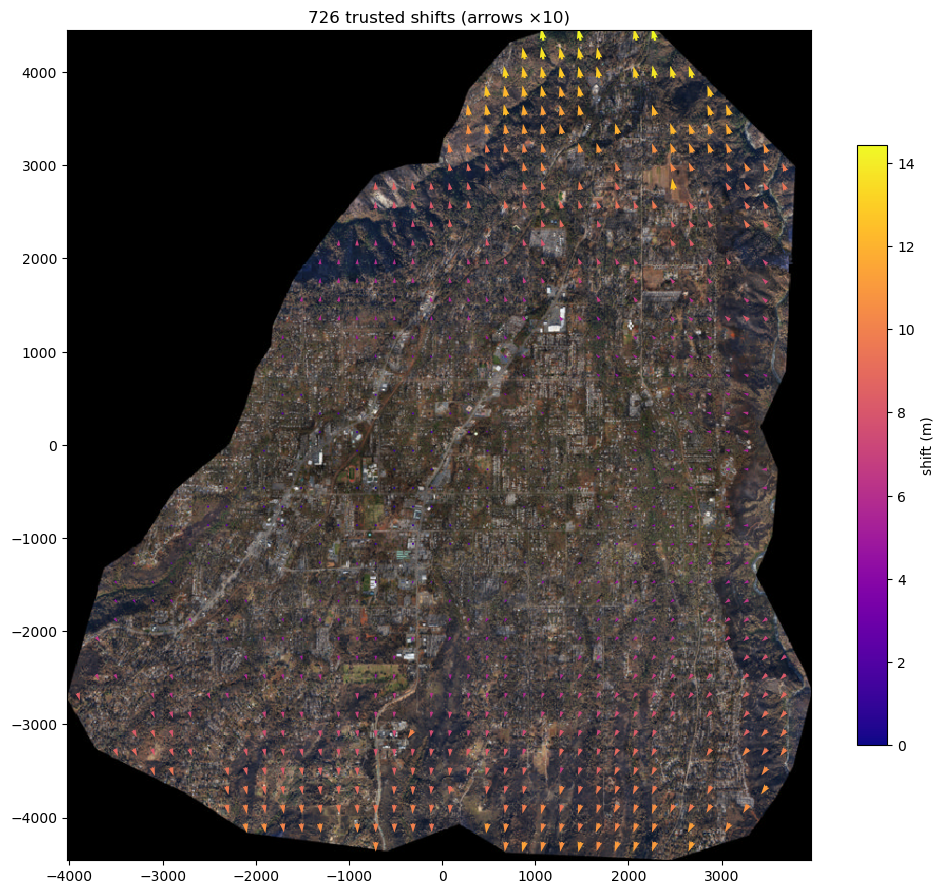

In [12]:
overview = cog.read([1, 2, 3], out_shape=(3, int((top - bottom) / 10), int((right - left) / 10)))
fig, ax = plt.subplots(figsize=(12, 13))
ax.imshow(np.moveaxis(overview, 0, -1), extent=(left, right, bottom, top))
arrows = ax.quiver(trusted['x'], trusted['y'], trusted['dx'], trusted['dy'], trusted['shift'],
                   angles='xy', scale_units='xy', scale=0.1, cmap='plasma', width=0.003)
fig.colorbar(arrows, ax=ax, shrink=0.6, label='shift (m)')
ax.set_title(f'{len(trusted)} trusted shifts (arrows ×10)')
plt.show()

# Part 3: understanding the shifts

The map shows one smooth pattern rather than local jumps: in the north the
image is off to the north, in the south to the south, and in the middle hardly
at all. So we first try the simplest model that can do that, a **linear
(affine) model**: each of dx and dy is a flat plane over the map,

    dx = a0 + a1·x + a2·y
    dy = b0 + b1·x + b2·y

with x, y in metres from the COG's centre. Each coefficient means something:

- `a0`, `b0`: the offset at the centre, m;
- `a1`: how much too wide (+) or too narrow (−) the image is east–west, per
  metre (×100 = %);
- `b2`: the same north–south;
- `a2`, `b1`: rotation or shear.

`np.linalg.lstsq` finds the coefficients with the smallest squared misfit
over the trusted cells (least squares). The **residual** of a cell is what the
model does not explain: its measured shift minus the model's.

In [13]:
def fit(cells, columns):
    '''Least-squares fit of dx and dy on columns (plus a constant).

    Returns the coefficients for dx and for dy (constant first), and the
    residuals (dx, dy) of every cell.
    '''
    A = np.column_stack([np.ones(len(cells))] + [cells[c].to_numpy() for c in columns])
    coef_x, *_ = np.linalg.lstsq(A, cells['dx'].to_numpy(), rcond=None)
    coef_y, *_ = np.linalg.lstsq(A, cells['dy'].to_numpy(), rcond=None)
    return coef_x, coef_y, cells['dx'].to_numpy() - A @ coef_x, cells['dy'].to_numpy() - A @ coef_y


trusted = cells[cells['trusted']].copy()
(a0, a1, a2), (b0, b1, b2), rx, ry = fit(trusted, ['x', 'y'])
trusted['residual'] = np.hypot(rx, ry)
print(f'offset at the centre:   dx {a0:+.2f} m, dy {b0:+.2f} m')
print(f'east-west scale (a1):   {a1 * 100:+.3f} %  ({a1 * 4000:+.1f} m at 4 km from the centre)')
print(f'north-south scale (b2): {b2 * 100:+.3f} %  ({b2 * 4000:+.1f} m at 4 km from the centre)')
print(f'rotation/shear (a2, b1): {a2:+.6f}, {b1:+.6f}  ({a2 * 4000:+.2f}, {b1 * 4000:+.2f} m at 4 km)')
print()
print('shift:    ', trusted['shift'].describe(percentiles=[0.5, 0.9, 0.99]).round(2)[['50%', '90%', '99%', 'max']].to_dict())
print('residual: ', trusted['residual'].describe(percentiles=[0.5, 0.9, 0.99]).round(2)[['50%', '90%', '99%', 'max']].to_dict())

offset at the centre:   dx -1.00 m, dy +1.21 m
east-west scale (a1):   -0.126 %  (-5.0 m at 4 km from the centre)
north-south scale (b2): +0.279 %  (+11.2 m at 4 km from the centre)
rotation/shear (a2, b1): +0.000031, +0.000025  (+0.12, +0.10 m at 4 km)

shift:     {'50%': 6.71, '90%': 10.6, '99%': 13.51, 'max': 14.43}
residual:  {'50%': 0.45, '90%': 0.91, '99%': 1.58, 'max': 4.94}


The model explains nearly all of it: the shifts have a median of 6.5 m, what is
left a median of about 0.5 m, which is about what we can measure (0.5 m
pixels). Rotation and shear are negligible (about 0.1 m at 4 km).

### Is there relief displacement too?

If the vendor had orthorectified onto a flat or too smooth height model, the
shift would also depend on the ground height. So we add `ground` to the model
and see how much the residual drops.

In [14]:
*_, rx_g, ry_g = fit(trusted, ['x', 'y', 'ground'])
residual_g = np.hypot(rx_g, ry_g)
print(f'x, y:          median residual {trusted["residual"].median():.2f} m, 90% {trusted["residual"].quantile(0.9):.2f} m')
print(f'x, y, ground:  median residual {np.median(residual_g):.2f} m, 90% {np.quantile(residual_g, 0.9):.2f} m')
print()
print('correlation of the residual with ground:', round(np.corrcoef(trusted['residual'], trusted['ground'])[0, 1], 2),
      ' with relief:', round(np.corrcoef(trusted['residual'], trusted['relief'])[0, 1], 2))
print('median residual by lidar period:', trusted.groupby('lidar')['residual'].median().round(2).to_dict())

x, y:          median residual 0.45 m, 90% 0.91 m
x, y, ground:  median residual 0.44 m, 90% 0.92 m

correlation of the residual with ground: 0.05  with relief: 0.02
median residual by lidar period: {'after': 0.4, 'before': 0.46}


Adding the ground height barely helps, and the residual does not follow the
ground or the relief. So relief displacement is at most a small part of it;
the main error is the scale of the whole mosaic.

## What is left: the residuals on a map

The residuals of the trusted cells, drawn **100 times longer** than they are.
If something local were going on (a canyon, a seam between photos), the
arrows there would be long and point the same way.

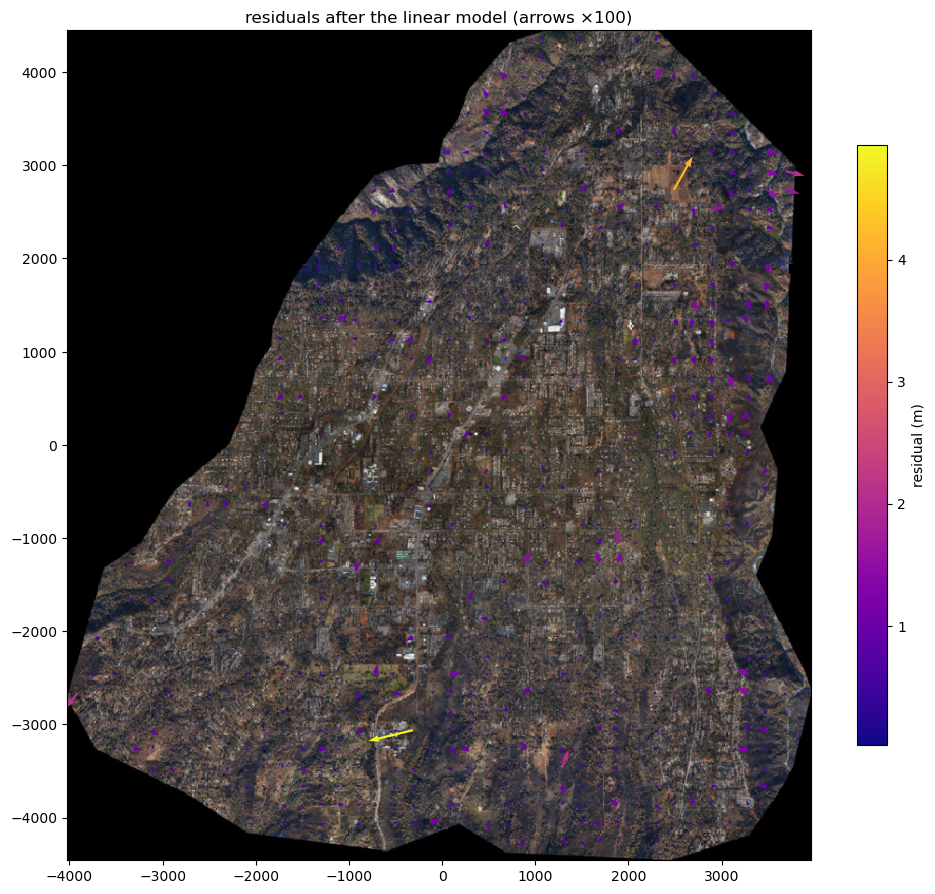

,x,y,dx,dy,z,deviation,ground,relief,lidar,residual
1002,-312.4,-3062.4,-5.5,-8.5,4.3,4.6,438.700012,65.599998,before,4.9
125,2487.6,2737.6,-2.0,12.5,4.1,4.1,677.700012,8.900000,before,4.1
908,-3912.4,-2662.4,2.5,-8.0,6.0,1.1,403.299988,29.400000,after,2.2
108,3687.6,2937.6,-3.5,9.0,7.1,0.6,479.100006,156.899994,before,2.1
1082,1287.6,-3462.4,-2.0,-6.5,4.4,1.9,466.200012,25.000000,before,2.0
647,1887.6,-1062.4,-3.5,0.0,6.5,1.0,578.700012,11.100000,before,1.7
131,3687.6,2737.6,-4.0,8.5,7.0,0.0,504.299988,152.899994,before,1.6
130,3487.6,2737.6,-4.0,8.0,4.8,0.7,450.200012,80.800003,before,1.6


In [15]:
fig, ax = plt.subplots(figsize=(12, 13))
ax.imshow(np.moveaxis(overview, 0, -1), extent=(left, right, bottom, top))
arrows = ax.quiver(trusted['x'], trusted['y'], rx, ry, trusted['residual'],
                   angles='xy', scale_units='xy', scale=0.01, cmap='plasma', width=0.003)
fig.colorbar(arrows, ax=ax, shrink=0.6, label='residual (m)')
ax.set_title('residuals after the linear model (arrows ×100)')
plt.show()

columns = ['x', 'y', 'dx', 'dy', 'z', 'deviation', 'ground', 'relief', 'lidar', 'residual']
trusted.sort_values('residual', ascending=False)[columns].head(8).round(1)

The two largest residuals (about 4–5 m) are cells that also disagree with
their neighbours by more than 4 m and have a low `z` (just above 4): bad
matches, not real distortion. The next ones are about 2 m, some of them in the
steep north-east corner. Everything else is under about 1.5 m.

## A clue to the cause

The two scales differ: the image is too tall north–south and too narrow
east–west. On the ellipsoid, a degree of latitude and a degree of longitude
(times cos latitude) are not the same distance: north–south uses the
meridian's radius of curvature *M*, east–west the prime vertical's *N*, and
*N* is larger. Someone converting degrees to metres with **one** radius for
both would get exactly this kind of error, and the ratio of the two scales
would be *N*/*M*.

In [16]:
a, e2 = 6378137.0, 0.00669437999014  # WGS 84
lat = np.radians(39.7642484434766)   # the COG's centre
w = 1 - e2 * np.sin(lat) ** 2
N = a / np.sqrt(w)                   # prime vertical (east-west)
M = a * (1 - e2) / w ** 1.5          # meridian (north-south)
print(f'N / M at the centre:            {N / M:.5f}')
print(f'(1 + b2) / (1 + a1) of the fit:  {(1 + b2) / (1 + a1):.5f}')

N / M at the centre:            1.00398
(1 + b2) / (1 + a1) of the fit:  1.00405


They agree to within about 1 part in 10,000 (0.4 m at 4 km). That is a strong
hint, not a proof.

## What it means for the fix

A linear error can be undone exactly by changing the GeoTIFF's
**geotransform** (its corner and pixel size, plus rotation terms), without
resampling a single pixel. Ignoring the tiny rotation, the true pixel size is
the stated one divided by the scale:

In [17]:
print(f'stated pixel size: {cog.res[0] * 100:.4f} x {cog.res[1] * 100:.4f} cm')
print(f'true pixel size:   {cog.res[0] / (1 + a1) * 100:.4f} cm east-west x {cog.res[1] / (1 + b2) * 100:.4f} cm north-south')

stated pixel size: 4.1111 x 4.1111 cm
true pixel size:   4.1163 cm east-west x 4.0997 cm north-south


**Next (part 4):** compute the corrected geotransform (the full affine, rotation
included), write it into a VRT or a copy of the COG (never the original),
measure again with `match` to check that the shifts are gone, and then build
the web COG from it.

# Part 4: correcting the georeferencing

### The geotransform

A GeoTIFF or VRT places its pixels with six numbers, the **geotransform**
(X0, w, 0, Y0, 0, −h): the top-left corner (X0, Y0) and the pixel width w and
height h. Pixel (col, row) lies at

    x = X0 + col · w        y = Y0 − row · h

The two zeros are rotation terms.

### Turning the fit around

Part 3 found where the image shows a point that truly lies at (x, y):

    x_image = a0 + (1 + a1) · x        y_image = b0 + (1 + b2) · y

(we leave out the rotation terms `a2` and `b1`: at most 0.1 m at 4 km, below
what we can measure, and the image stays north-up, which every tool handles).
Solved for the true position:

    x = (x_image − a0) / (1 + a1)      y = (y_image − b0) / (1 + b2)

The stated geotransform gives x_image and y_image of every pixel. Putting it
into these formulas gives a new geotransform that places every pixel where it
truly is:

    X0' = (X0 − a0) / (1 + a1)     w' = w / (1 + a1)
    Y0' = (Y0 − b0) / (1 + b2)     h' = h / (1 + b2)

In [18]:
with rasterio.open(COG) as mosaic:
    X0, w, _, Y0, _, minus_h = mosaic.transform.to_gdal()
h = -minus_h
corrected_transform = ((X0 - a0) / (1 + a1), w / (1 + a1), 0.0,
                       (Y0 - b0) / (1 + b2), 0.0, -h / (1 + b2))
print('stated:   ', (X0, w, 0.0, Y0, 0.0, -h))
print('corrected:', tuple(round(float(v), 6) for v in corrected_transform))
print(f'top-left corner moves {corrected_transform[0] - X0:+.2f} m east, {corrected_transform[3] - Y0:+.2f} m north')

stated:    (-4027.416825, 0.041111, 0.0, 4452.593539, 0.0, -0.041111)
corrected: (-4031.480329, 0.041163, 0.0, 4438.998739, 0.0, -0.040997)
top-left corner moves -4.06 m east, -13.59 m north


### Writing the corrected VRT

A copy of the mosaic VRT with the new geotransform. It still points to the
same 495 tiles, so no pixel is copied or resampled, and the tiles themselves
are not touched. It goes next to the other COGs on `/media/disk1`, under a new
name.

In [19]:
CORRECTED = '/media/disk1/waldoair_campfire_cog/waldoair_campfire_v2_corrected.vrt'

source = gdal.Open(COG)
copy = gdal.GetDriverByName('VRT').CreateCopy(CORRECTED, source)
copy.SetGeoTransform(corrected_transform)
copy = source = None  # closing a VRT writes it
print(gdal.Info(CORRECTED, format='json')['geoTransform'])

[-4031.4803293160294, 0.0411626598711011, 0.0, 4438.998739060859, 0.0, -0.0409966399386515]


### Checking: measuring again

We run `match` again at every trusted cell, now on the corrected VRT. If the
correction is right, what is left should be as small as the residuals in
part 3 (median about 0.5 m), everywhere: no more growth towards the edges.

Only cells whose matching window lies entirely inside the corrected image
count: the correction moves the image (up to 13.6 m at the top edge), so the
window of a cell at the edge can stick out past it, and rasterio then
stretches the part it can read to fill the window, which gives a false shift.

`match` and `show` read from `cog`, so we point `cog` to the corrected VRT.

In [20]:
original = cog
cog = rasterio.open(CORRECTED)

half = CELL / 2 + SEARCH
b = cog.bounds
fits = ((trusted['x'] - half >= b.left) & (trusted['x'] + half <= b.right)
        & (trusted['y'] - half >= b.bottom) & (trusted['y'] + half <= b.top))
check = trusted[fits].copy()
print(f'{len(check)} of {len(trusted)} trusted cells fit inside the corrected image')

after = []
for x, y in check[['x', 'y']].to_numpy():
    dx, dy, peak, z, on_border = match(x, y)
    after.append({'dx_after': dx, 'dy_after': dy, 'z_after': z})
check = check.join(pd.DataFrame(after, index=check.index))
check['shift_after'] = np.hypot(check['dx_after'], check['dy_after'])

stats = pd.DataFrame({'before': check['shift'], 'after': check['shift_after']})
print(stats.describe(percentiles=[0.5, 0.9, 0.99]).round(2).loc[['50%', '90%', '99%', 'max']].to_string())
far = np.hypot(check['x'], check['y']) > 3000
print(f'\nmore than 3 km from the centre: median {check.loc[far, "shift"].median():.1f} m before, '
      f'{check.loc[far, "shift_after"].median():.1f} m after')

columns = ['x', 'y', 'shift', 'z', 'deviation', 'residual', 'dx_after', 'dy_after', 'shift_after', 'z_after']
check.sort_values('shift_after', ascending=False)[columns].head(5).round(1)

722 of 726 trusted cells fit inside the corrected image


     before  after
50%    6.69   0.50
90%   10.59   1.00
99%   13.24   1.58
max   13.83  15.03

more than 3 km from the centre: median 8.7 m before, 0.5 m after


,x,y,shift,z,deviation,residual,dx_after,dy_after,shift_after,z_after
150,2687.6,2537.6,8.5,4.1,0.6,0.9,-15.0,1.0,15.0,3.6
1002,-312.4,-3062.4,10.1,4.3,4.6,4.9,-5.0,-1.0,5.1,4.0
908,-3912.4,-2662.4,8.4,6.0,1.1,2.2,-1.0,-2.0,2.2,5.6
108,3687.6,2937.6,9.7,7.1,0.6,2.1,2.0,0.0,2.0,5.6
151,2887.6,2537.6,9.0,4.4,1.4,1.5,1.5,0.5,1.6,4.4


After the correction, the shifts are as small as the residuals of the fit in
part 3: median 0.5 m (our pixel size), 99% under about 1.6 m, and more than
3 km from the centre the median drops from 8.7 m to 0.5 m. The few cells still
off by more are not trustworthy measurements: the worst has `z_after` under 4
with its peak on the search border, and the next is the cell that already
disagreed with its neighbours by 4.6 m in part 2. After those, about 2 m at
most, in the steep north-east corner and at the western edge: perhaps a little
relief displacement after all, but small.

### By eye

The south-east cell and, in the far north, the trusted cell with the most
buildings, before (left) and after (right), with
the lidar outlines where the lidar has them, not moved.

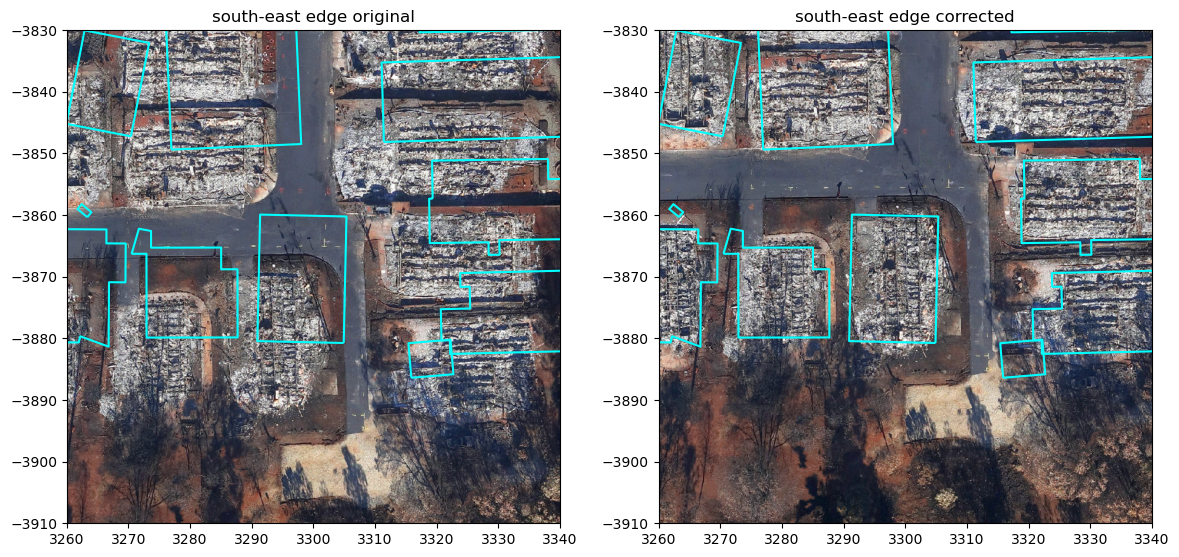

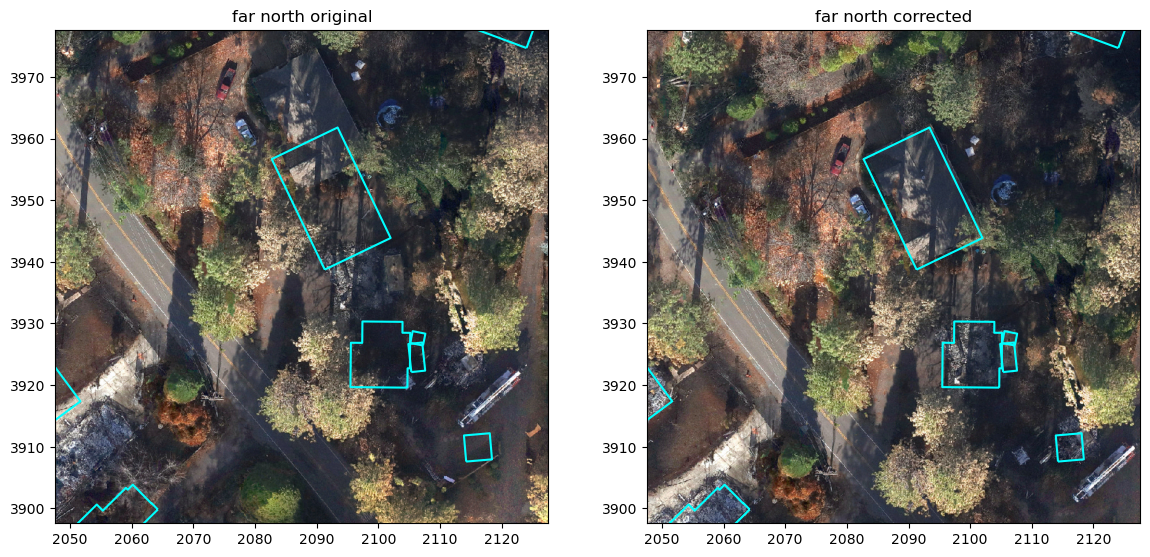

In [21]:
def compare(x, y, size=80, title=''):
    '''The image around (x, y), original and corrected, with the lidar outlines unmoved.'''
    left_, bottom_, right_, top_ = x - size / 2, y - size / 2, x + size / 2, y + size / 2
    outlines = buildings.cx[left_ - 20:right_ + 20, bottom_ - 20:top_ + 20].boundary
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, dataset, label in zip(axes, [original, cog], ['original', 'corrected']):
        window = from_bounds(left_, bottom_, right_, top_, dataset.transform)
        rgb = dataset.read([1, 2, 3], window=window, out_shape=(3, 800, 800))
        ax.imshow(np.moveaxis(rgb, 0, -1), extent=(left_, right_, bottom_, top_))
        outlines.plot(ax=ax, color='cyan', linewidth=1.5)
        ax.set_xlim(left_, right_)
        ax.set_ylim(bottom_, top_)
        ax.set_title(f'{title} {label}')
    plt.show()


compare(3300, -3870, title='south-east edge')
north = check[check['y'] > 3500]
in_view = [len(buildings.cx[x - 40:x + 40, y - 40:y + 40]) for x, y in north[['x', 'y']].to_numpy()]
x, y = north[['x', 'y']].to_numpy()[np.argmax(in_view)]
compare(x, y, title='far north')

## Next: a new web COG

The app needs the corrected mosaic as a web COG (EPSG:3857, blocks aligned
with the web-map tiles), like `waldoair_campfire_web_v2.tif`. That one was made
with the command below (from `waldoair_campfire_web_v2.build.log`), from a VRT
of the tiles; for the new one, the input is the corrected VRT and the output a
new name. It resamples every pixel once and took about 2 hours for v2; run in a terminal, not from here:

```
gdal_translate --config GDAL_CACHEMAX 4096 --config CPL_TMPDIR /media/disk1/waldoair_campfire_cog \
  -of COG /media/disk1/waldoair_campfire_cog/waldoair_campfire_v2_corrected.vrt \
  /media/disk1/waldoair_campfire_cog/waldoair_campfire_web_v3.tif \
  -co COMPRESS=JPEG -co QUALITY=90 -co RESAMPLING=BILINEAR -co NUM_THREADS=ALL_CPUS \
  -co TILING_SCHEME=GoogleMapsCompatible -co ZOOM_LEVEL=22 -co ALIGNED_LEVELS=8 \
  -co BLOCKSIZE=256 -co OVERVIEW_QUALITY=90 -co BIGTIFF=YES
```

Then: measure it once more (a few cells, through the lidar), and upload it to
R2 under a new key, next to v2.